In [1]:
%pip install pandas numpy matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [3]:
def load_dataset(file_path="sales_data.csv"):
    try:
        df = pd.read_csv(file_path)
        print("Dataset loaded successfully!")
        print("Number of records:", len(df))
        return df
    except FileNotFoundError:
        print("CSV file not found. Keep sales_data.csv beside this notebook.")
        print("Current folder:", os.getcwd())
        print("Files in this folder:", os.listdir())
        return pd.DataFrame()

data = load_dataset()

Dataset loaded successfully!
Number of records: 120


In [4]:
if not data.empty:
    display(data.head())
    print("Dataset shape:", data.shape)
    print("Column names:", data.columns.tolist())
    data.info()

,SaleID,Date,Product,Region,Quantity,UnitPrice,Sales,Profit,Year
0,1,2025-11-30,Headphones,North,2,2417,4834,456.75,2025
1,2,2025-10-26,Monitor,North,1,12991,12991,3402.87,2025
2,3,2025-08-11,Phone,West,1,14816,14816,1392.28,2025
3,4,2025-01-31,Laptop,Central,5,58910,294550,30857.17,2025
4,5,2025-10-23,Phone,Central,5,14027,70135,11175.04,2025


Dataset shape: (120, 9)
Column names: ['SaleID', 'Date', 'Product', 'Region', 'Quantity', 'UnitPrice', 'Sales', 'Profit', 'Year']
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   SaleID     120 non-null    int64  
 1   Date       120 non-null    str    
 2   Product    120 non-null    str    
 3   Region     120 non-null    str    
 4   Quantity   120 non-null    int64  
 5   UnitPrice  120 non-null    int64  
 6   Sales      120 non-null    int64  
 7   Profit     120 non-null    float64
 8   Year       120 non-null    int64  
dtypes: float64(1), int64(5), str(3)
memory usage: 11.1 KB


In [25]:
def clean_data(df):
    df = df.copy()
    df.drop_duplicates(inplace=True)
    for column in df.select_dtypes(include="number").columns:
        df[column] = df[column].fillna(df[column].mean())
    for column in df.select_dtypes(include=["object", "str"]).columns:
        df[column] = df[column].fillna("Unknown")
    return df

data = clean_data(data)
print("Missing values after cleaning:")
print(data.isnull().sum())

Missing values after cleaning:
SaleID       0
Date         0
Product      0
Region       0
Quantity     0
UnitPrice    0
Sales        0
Profit       0
Year         0
dtype: int64


In [6]:
print("First five rows:")
display(data.head())
print("Last five rows:")
display(data.tail())
print("Data types:")
print(data.dtypes)
print("Summary statistics:")
display(data.describe(include="all"))

First five rows:


,SaleID,Date,Product,Region,Quantity,UnitPrice,Sales,Profit,Year
0,1,2025-11-30,Headphones,North,2,2417,4834,456.75,2025
1,2,2025-10-26,Monitor,North,1,12991,12991,3402.87,2025
2,3,2025-08-11,Phone,West,1,14816,14816,1392.28,2025
3,4,2025-01-31,Laptop,Central,5,58910,294550,30857.17,2025
4,5,2025-10-23,Phone,Central,5,14027,70135,11175.04,2025


Last five rows:


,SaleID,Date,Product,Region,Quantity,UnitPrice,Sales,Profit,Year
115,116,2025-03-02,Keyboard,Central,4,2171,8684,1040.78,2025
116,117,2025-05-29,Laptop,West,4,45573,182292,17371.12,2025
117,118,2025-07-18,Monitor,South,4,11401,45604,12008.03,2025
118,119,2025-02-16,Phone,South,1,31053,31053,7126.58,2025
119,120,2025-11-05,Headphones,Central,3,1343,4029,547.60,2025


Data types:
SaleID         int64
Date             str
Product          str
Region           str
Quantity       int64
UnitPrice      int64
Sales          int64
Profit       float64
Year           int64
dtype: object
Summary statistics:


,SaleID,Date,Product,Region,Quantity,UnitPrice,Sales,Profit,Year
count,120.000000,120,120,120,120.000000,120.000000,120.000000,120.000000,120.0
unique,NaN,107,7,5,NaN,NaN,NaN,NaN,NaN
top,NaN,2025-01-31,Monitor,Central,NaN,NaN,NaN,NaN,NaN
freq,NaN,2,24,30,NaN,NaN,NaN,NaN,NaN
mean,60.500000,NaN,NaN,NaN,2.816667,16100.283333,50088.500000,8449.591000,2025.0
std,34.785054,NaN,NaN,NaN,1.472341,17879.041358,72646.913995,12344.464649,0.0
min,1.000000,NaN,NaN,NaN,1.000000,339.000000,424.000000,88.800000,2025.0
25%,30.750000,NaN,NaN,NaN,1.000000,1734.000000,4019.250000,652.902500,2025.0
50%,60.500000,NaN,NaN,NaN,3.000000,10636.000000,18126.000000,2977.360000,2025.0
75%,90.250000,NaN,NaN,NaN,4.000000,23273.000000,61115.500000,10397.215000,2025.0


In [7]:
sales_array = data["Sales"].to_numpy()
print("First 10 sales:", sales_array[:10])
print("Slice positions 3 to 7:", sales_array[2:7])
print("Total sales:", np.sum(sales_array))
print("Average sales:", round(np.mean(sales_array), 2))

First 10 sales: [  4834  12991  14816 294550  70135  30240  16353  31057  16246   5875]
Slice positions 3 to 7: [ 14816 294550  70135  30240  16353]
Total sales: 6010620
Average sales: 50088.5


In [8]:
product_name = input("Enter a product name to search: ").strip()
if product_name:
    result = data[data["Product"].str.contains(product_name, case=False, na=False)]
    display(result)
    if result.empty:
        print("No matching product found.")
else:
    print("No product name entered.")

Enter a product name to search:  Laptop


,SaleID,Date,Product,Region,Quantity,UnitPrice,Sales,Profit,Year
3,4,2025-01-31,Laptop,Central,5,58910,294550,30857.17,2025
31,32,2025-10-02,Laptop,North,5,49956,249780,67388.08,2025
34,35,2025-09-03,Laptop,West,4,60269,241076,34322.10,2025
47,48,2025-12-31,Laptop,South,1,57731,57731,10137.94,2025
59,60,2025-06-16,Laptop,Central,5,47023,235115,43765.55,2025
62,63,2025-06-16,Laptop,Central,1,59524,59524,16349.58,2025
66,67,2025-06-11,Laptop,North,4,59487,237948,50975.86,2025
78,79,2025-02-07,Laptop,East,2,58936,117872,31550.79,2025
80,81,2025-08-21,Laptop,North,3,48987,146961,21725.30,2025
99,100,2025-11-19,Laptop,South,3,54969,164907,15978.92,2025


In [9]:
print("Top 10 sales records:")
display(data.sort_values("Sales", ascending=False).head(10))

region_name = input("Enter a region (North/South/East/West/Central): ").strip()
filtered_data = data[data["Region"].str.lower() == region_name.lower()]
print("Matching records:")
display(filtered_data)
if filtered_data.empty:
    print("No matching region found.")

Top 10 sales records:


,SaleID,Date,Product,Region,Quantity,UnitPrice,Sales,Profit,Year
106,107,2025-05-06,Laptop,West,5,67304,336520,44675.92,2025
102,103,2025-08-08,Laptop,Central,5,65556,327780,35354.85,2025
3,4,2025-01-31,Laptop,Central,5,58910,294550,30857.17,2025
31,32,2025-10-02,Laptop,North,5,49956,249780,67388.08,2025
34,35,2025-09-03,Laptop,West,4,60269,241076,34322.10,2025
66,67,2025-06-11,Laptop,North,4,59487,237948,50975.86,2025
59,60,2025-06-16,Laptop,Central,5,47023,235115,43765.55,2025
113,114,2025-12-11,Laptop,North,4,53807,215228,47013.77,2025
116,117,2025-05-29,Laptop,West,4,45573,182292,17371.12,2025
99,100,2025-11-19,Laptop,South,3,54969,164907,15978.92,2025


Enter a region (North/South/East/West/Central):  North


Matching records:


,SaleID,Date,Product,Region,Quantity,UnitPrice,Sales,Profit,Year
0,1,2025-11-30,Headphones,North,2,2417,4834,456.75,2025
1,2,2025-10-26,Monitor,North,1,12991,12991,3402.87,2025
12,13,2025-11-08,Headphones,North,4,1979,7916,820.20,2025
19,20,2025-11-09,Keyboard,North,3,944,2832,506.19,2025
27,28,2025-12-02,Phone,North,5,32237,161185,27615.62,2025
29,30,2025-04-08,Keyboard,North,4,727,2908,805.32,2025
31,32,2025-10-02,Laptop,North,5,49956,249780,67388.08,2025
38,39,2025-11-26,Tablet,North,5,24767,123835,27149.51,2025
42,43,2025-01-15,Keyboard,North,3,2097,6291,1497.40,2025
49,50,2025-07-25,Mouse,North,4,1248,4992,1123.00,2025


In [10]:
data["DiscountedSales"] = (data["Sales"] * 0.90).round(2)
display(data[["Product", "Sales", "DiscountedSales"]].head(10))

,Product,Sales,DiscountedSales
0,Headphones,4834,4350.6
1,Monitor,12991,11691.9
2,Phone,14816,13334.4
3,Laptop,294550,265095.0
4,Phone,70135,63121.5
5,Phone,30240,27216.0
6,Monitor,16353,14717.7
7,Phone,31057,27951.3
8,Monitor,16246,14621.4
9,Mouse,5875,5287.5


In [11]:
region_name = input("Enter a region to save: ").strip()
region_data = data[data["Region"].str.lower() == region_name.lower()]
if not region_data.empty:
    region_data.to_csv("region_data.csv", index=False)
    print("Saved", len(region_data), "records to region_data.csv")
else:
    print("No records found for that region.")

Enter a region to save:  South


Saved 23 records to region_data.csv


In [12]:
region_sales = data.groupby("Region", as_index=False)["Sales"].sum()
targets = pd.DataFrame({"Region": ["North", "South"], "Target": [200000, 180000]})

print("CONCAT:")
display(pd.concat([region_sales.head(2), region_sales.tail(2)], ignore_index=True))

print("MERGE:")
display(pd.merge(region_sales, targets, on="Region", how="left"))

print("JOIN:")
display(region_sales.set_index("Region").join(targets.set_index("Region"), how="left"))

CONCAT:


,Region,Sales
0,Central,1424826
1,East,1008638
2,South,935442
3,West,1272714


MERGE:


,Region,Sales,Target
0,Central,1424826,NaN
1,East,1008638,NaN
2,North,1369000,200000.0
3,South,935442,180000.0
4,West,1272714,NaN


JOIN:


,Sales,Target
Region,,
Central,1424826,NaN
East,1008638,NaN
North,1369000,200000.0
South,935442,180000.0
West,1272714,NaN


In [13]:
sales = data["Sales"]
print("Total:", sales.sum())
print("Mean:", round(sales.mean(), 2))
print("Median:", sales.median())
print("Minimum:", sales.min())
print("Maximum:", sales.max())
print("Standard deviation:", round(sales.std(), 2))
print("Variance:", round(sales.var(), 2))
print("Percentiles:")
display(sales.quantile([0.25, 0.50, 0.75]))

Total: 6010620
Mean: 50088.5
Median: 18126.0
Minimum: 424
Maximum: 336520
Standard deviation: 72646.91
Variance: 5277574113.06
Percentiles:


0.25     4019.25
0.50    18126.00
0.75    61115.50
Name: Sales, dtype: float64

In [14]:
print("Sales summary by region:")
display(data.groupby("Region")["Sales"].agg(["sum", "mean", "count"]))
print("Pivot table: Region by Product")
display(pd.pivot_table(data, values="Sales", index="Region",
                       columns="Product", aggfunc="sum", fill_value=0))

Sales summary by region:


,sum,mean,count
Region,,,
Central,1424826,47494.200000,30
East,1008638,40345.520000,25
North,1369000,57041.666667,24
South,935442,40671.391304,23
West,1272714,70706.333333,18


Pivot table: Region by Product


Product,Headphones,Keyboard,Laptop,Monitor,Mouse,Phone,Tablet
Region,,,,,,,
Central,18644,24202,916969,211795,8941,224561,19714
East,24425,8141,117872,207224,8033,218237,424706
North,16978,14439,849917,73434,9486,257705,147041
South,19810,17971,222638,281608,8606,101310,283499
West,22280,10236,759888,86066,5875,137230,251139


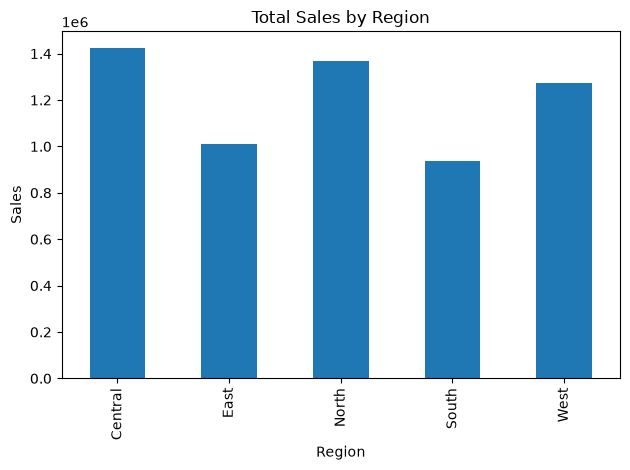

In [15]:
data.groupby("Region")["Sales"].sum().plot(kind="bar", title="Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

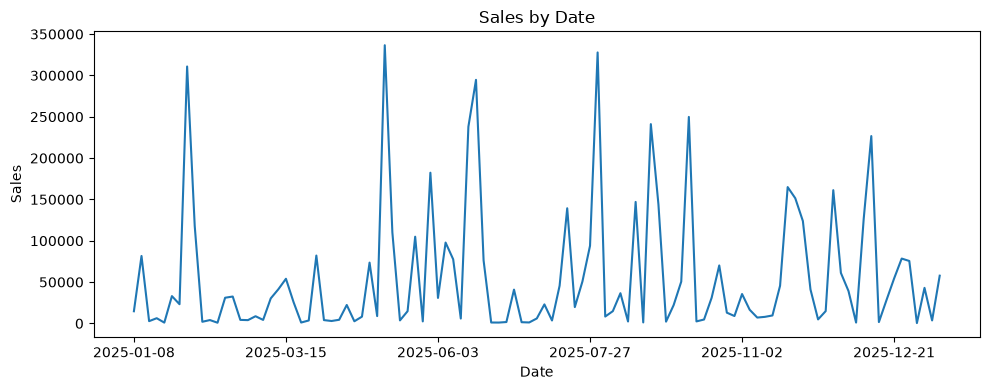

In [16]:
daily_sales = data.groupby("Date")["Sales"].sum().sort_index()
daily_sales.plot(kind="line", title="Sales by Date", figsize=(10, 4))
plt.xlabel("Date")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

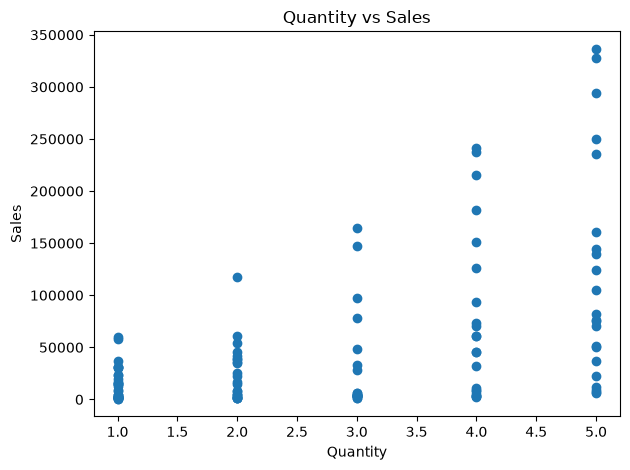

In [17]:
plt.scatter(data["Quantity"], data["Sales"])
plt.title("Quantity vs Sales")
plt.xlabel("Quantity")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

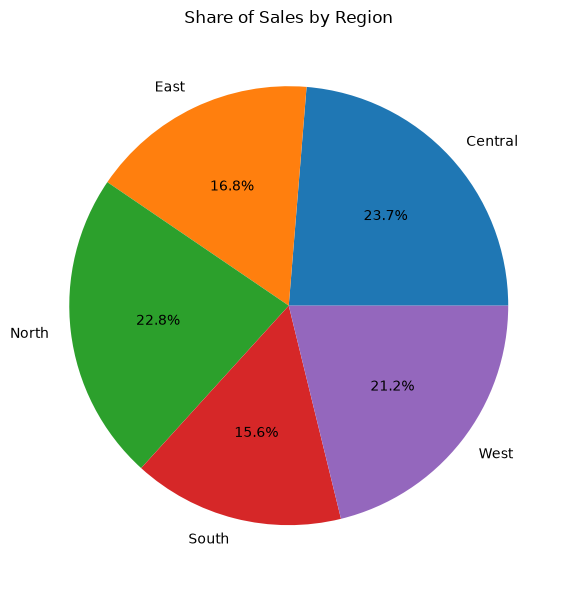

In [18]:
data.groupby("Region")["Sales"].sum().plot(kind="pie", autopct="%1.1f%%", figsize=(6,6))
plt.title("Share of Sales by Region")
plt.ylabel("")
plt.tight_layout()
plt.show()

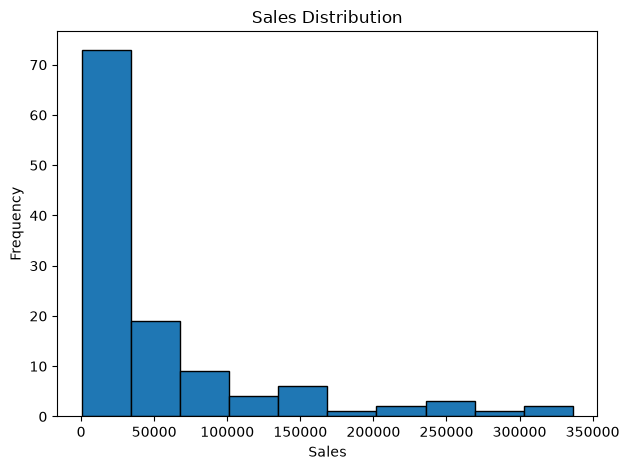

In [19]:
plt.hist(data["Sales"], bins=10, edgecolor="black")
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

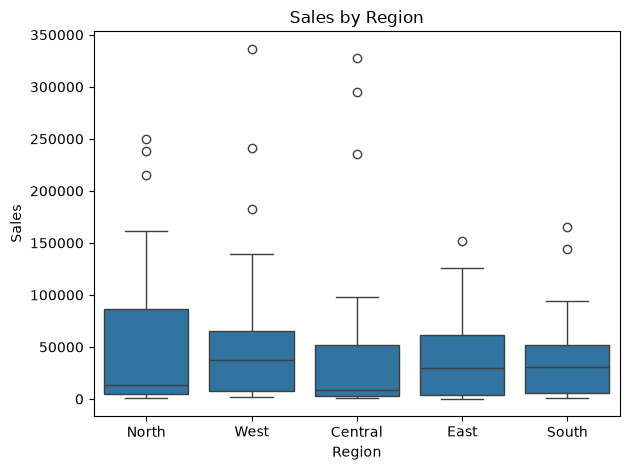

In [20]:
sns.boxplot(data=data, x="Region", y="Sales")
plt.title("Sales by Region")
plt.tight_layout()
plt.show()

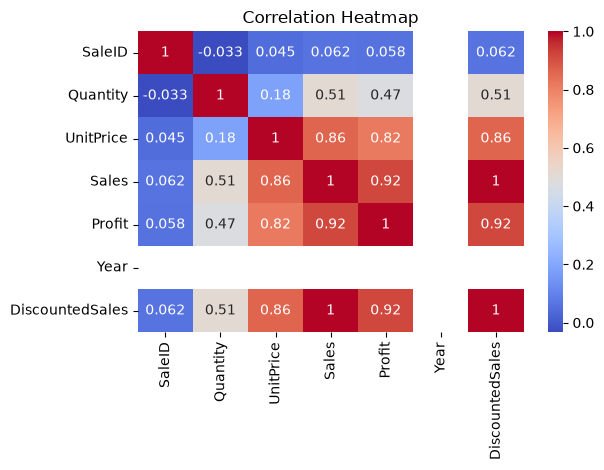

In [21]:
numeric_data = data.select_dtypes(include="number")
sns.heatmap(numeric_data.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

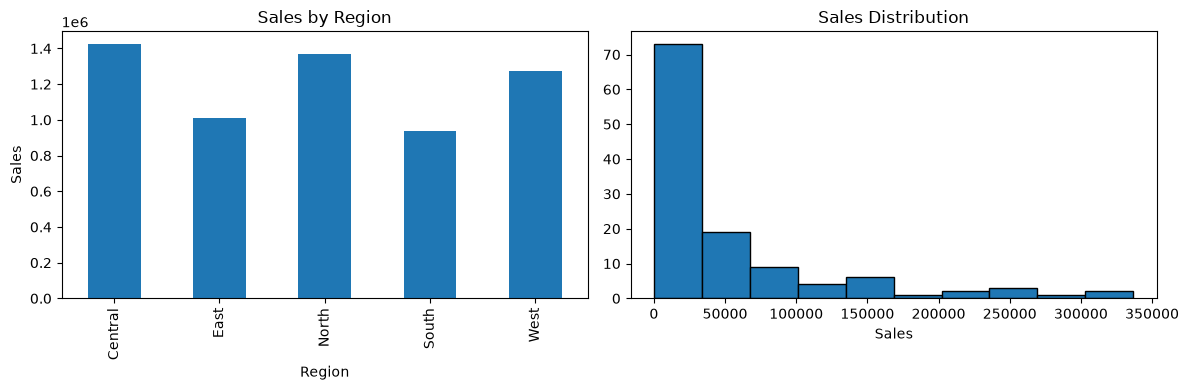

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data.groupby("Region")["Sales"].sum().plot(kind="bar", ax=axes[0], title="Sales by Region")
axes[0].set_ylabel("Sales")
axes[1].hist(data["Sales"], bins=10, edgecolor="black")
axes[1].set_title("Sales Distribution")
axes[1].set_xlabel("Sales")
plt.tight_layout()
plt.show()

In [23]:
file_name = input("Enter chart file name (example: sales_chart.png): ").strip()
if file_name:
    if not file_name.lower().endswith((".png", ".jpg", ".jpeg")):
        file_name += ".png"
    plt.savefig(file_name, bbox_inches="tight")
    print("Chart saved as:", file_name)
else:
    print("No file name entered.")

Enter chart file name (example: sales_chart.png):  sales_chart.png


Chart saved as: sales_chart.png


<Figure size 640x480 with 0 Axes>

In [26]:
data = load_dataset("sales_data.csv")
data = clean_data(data)
display(data.head())

Dataset loaded successfully!
Number of records: 120


,SaleID,Date,Product,Region,Quantity,UnitPrice,Sales,Profit,Year
0,1,2025-11-30,Headphones,North,2,2417,4834,456.75,2025
1,2,2025-10-26,Monitor,North,1,12991,12991,3402.87,2025
2,3,2025-08-11,Phone,West,1,14816,14816,1392.28,2025
3,4,2025-01-31,Laptop,Central,5,58910,294550,30857.17,2025
4,5,2025-10-23,Phone,Central,5,14027,70135,11175.04,2025
